# Inspect the preprocessing contract

Verify how the same observation is normalized, tiled, augmented and decoded at serving time.

In [1]:
from pathlib import Path
import sys
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "configs/dataset.yaml").exists())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.schema import ROOT, NAMES, MODELS, config


## Mask and radiometry stay aligned

In [2]:
from src.data import Tiles, rows, split
from src.schema import decode, dominant, tensor
data = ROOT / "data/processed"
cfg = config("dataset")
ds = Tiles(data, split(rows(data))["train"], cfg["tile"], cfg["preprocessing"])
sample, mask, label = ds[0]
assert sample.shape == (2,64,64) and label == dominant(mask.numpy())
print("Valid input pixels", int(sample[1].sum()), "· dominant image class ID", label)

Valid input pixels 4096 · dominant image class ID 1


## Paired augmentation

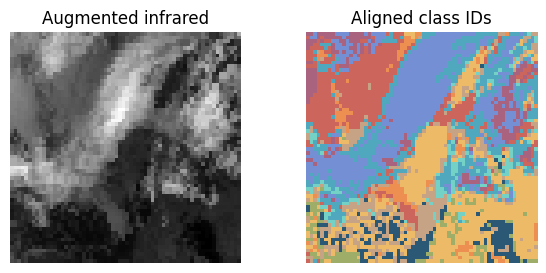

In [3]:
from src.data import augment
from src.schema import color_mask
scene, target, record = ds.scenes[0]
np.random.seed(42)
aug_ir, aug_mask = augment(scene[:64,:64],target[:64,:64],config("training")["augment"])
fig, axes = plt.subplots(1,2,figsize=(7,3))
axes[0].imshow(aug_ir,cmap="gray_r"); axes[0].set_title("Augmented infrared")
axes[1].imshow(color_mask(aug_mask)); axes[1].set_title("Aligned class IDs")
for ax in axes: ax.axis("off")
fig

## Round trip through the file-upload contract

In [4]:
file = ROOT/"examples/20170107T1800Z.png"
observation = decode(file.read_bytes(), file.name)
with np.load(data/"scenes/20170107T1800Z.npz") as paired:
    max_rounding_error = np.nanmax(np.abs(observation - paired["kelvin"]))
assert max_rounding_error < 0.006
print(f"Maximum centikelvin round-trip error: {max_rounding_error:.5f} K")

Maximum centikelvin round-trip error: 0.00003 K
